# Predicting the Severity of Road Traffic Accidents: EDA and Data Preparation
**ARTI 205 Machine Learning | Group 3 | Dr. Irfan Ullah**

Dataset: *Road Safety Data - Collisions 2024* and *Vehicles 2024*, UK Department for Transport (police STATS19 records).
Code meanings follow the official STATS20 2024 specification.

This notebook does three things:
1. **Explores** the data with Python charts (Week 4).
2. **Finds the data-quality issues** and fixes them (Week 5 and Week 6).
3. **Writes the final dataset** used for modelling: `../Data/UK_collisions_final.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path
from scipy.stats import chi2_contingency

RAW = Path("../Data/dft-road-casualty-statistics-collision-2024.csv")
VEH_RAW = Path("../Data/dft-road-casualty-statistics-vehicle-2024.csv")
OUT = Path("../Data/UK_collisions_final.csv")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# chart style: one blue for data, orange only to highlight, quiet grey grid
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": "Inter" if "Inter" in fonts else "DejaVu Sans",
    "font.size": 13, "axes.titlesize": 15, "axes.titleweight": "semibold",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "figure.dpi": 110, "axes.axisbelow": True, "savefig.dpi": 200, "savefig.bbox": "tight",
})
def save(fig, name):
    fig.savefig(FIG / name, facecolor="white")
    plt.show()

## 1. Load the raw data

In [2]:
raw = pd.read_csv(RAW, low_memory=False)
veh_cols = [
    "collision_index", "vehicle_reference", "vehicle_type", "age_of_driver",
    "vehicle_manoeuvre", "junction_location", "sex_of_driver",
    "journey_purpose_of_driver", "towing_and_articulation", "propulsion_code", "age_of_vehicle",
]
veh_raw = pd.read_csv(VEH_RAW, usecols=veh_cols, low_memory=False)
print(f"collisions: {raw.shape[0]:,} x {raw.shape[1]} columns | vehicles: {veh_raw.shape[0]:,} x {veh_raw.shape[1]} columns")
print("years:", raw["collision_year"].unique(), "| duplicate collision rows:", raw.duplicated().sum())
raw.head(3)

collisions: 100,927 x 44 columns | vehicles: 183,514 x 11 columns
years: [2024] | duplicate collision rows: 0


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417H103224,2024,17H103224,448894,532505,-1.24312,54.68523,17,3,2,...,-1,0,1,2,2,E01011983,3,1,0.000000,1.000000
1,202417M217924,2024,17M217924,452135,519436,-1.19517,54.56747,17,2,2,...,-1,0,1,3,2,E01012061,7,1,1.000000,0.000000
2,202417S204524,2024,17S204524,445427,522924,-1.29837,54.59946,17,3,2,...,0,0,2,1,2,E01012280,-1,0,0.111621,0.888379


In [3]:
# data types (Week 4): almost every column is an integer CODE for a category
raw.dtypes.value_counts()

int64      32
object      8
float64     4
Name: count, dtype: int64

## 2. Code labels (STATS20 2024 specification)
Most columns store numbers that stand for categories, e.g. `light_conditions = 6` means *darkness, no street lighting*.
We map them to labels so the charts and the model results are readable.
`-1` = data missing; `9` / `99` = unknown (self-reported).

In [4]:
SEVERITY = {1: "Fatal", 2: "Serious", 3: "Slight"}
LABELS = {
 "day_of_week": {1:"Sun",2:"Mon",3:"Tue",4:"Wed",5:"Thu",6:"Fri",7:"Sat"},
 "first_road_class": {1:"Motorway",2:"A(M)",3:"A",4:"B",5:"C",6:"Unclassified"},
 "road_type": {1:"Roundabout",2:"One way street",3:"Dual carriageway",6:"Single carriageway",7:"Slip road",9:"Unknown",-1:"Unknown"},
 "junction_detail": {0:"Not at junction",13:"T or staggered",16:"Crossroads",17:"More than 4 arms",18:"Private drive",19:"Other junction",99:"Unknown",-1:"Not applicable / missing"},
 "junction_control": {1:"Authorised person",2:"Traffic signal",3:"Stop sign",4:"Give way / uncontrolled",9:"Unknown",-1:"Not at junction"},
 "second_road_class": {0:"Not at junction",1:"Motorway",2:"A(M)",3:"A",4:"B",5:"C",6:"Unclassified",9:"Unknown",-1:"Unknown"},
 "pedestrian_crossing": {0:"None within 50 m",11:"School crossing patrol",12:"Other authorised person",13:"Zebra",14:"Pedestrian light crossing",15:"Pedestrian phase at signal",16:"Footbridge or subway",17:"Central refuge",99:"Unknown",-1:"Unknown"},
 "light_conditions": {1:"Daylight",4:"Dark, lights lit",5:"Dark, lights unlit",6:"Dark, no lighting",7:"Dark, lighting unknown",-1:"Unknown"},
 "weather_conditions": {1:"Fine",2:"Raining",3:"Snowing",4:"Fine + high winds",5:"Raining + high winds",6:"Snowing + high winds",7:"Fog or mist",8:"Other",9:"Unknown",-1:"Unknown"},
 "road_surface_conditions": {1:"Dry",2:"Wet or damp",3:"Snow",4:"Frost or ice",5:"Flood",9:"Unknown",-1:"Unknown"},
 "carriageway_hazards": {0:"No hazard",11:"Defective signals",12:"Defective signs/markings",13:"Roadworks",14:"Oil or diesel",15:"Mud",16:"Dislodged load",17:"Other object",18:"Previous collision",19:"Pedestrian in road",20:"Animal in road",21:"Defective surface",99:"Unknown",-1:"Unknown"},
 "urban_or_rural_area": {1:"Urban",2:"Rural",3:"Unallocated",-1:"Unallocated"},
}
df = raw.copy()
df["severity"] = df["collision_severity"].map(SEVERITY)
df["hour"] = pd.to_numeric(df["time"].str[:2], errors="coerce")
df["month"] = pd.to_datetime(df["date"], format="%d/%m/%Y").dt.month
lab = df.copy()
for col, m in LABELS.items():
    lab[col] = lab[col].map(m)
print("unmapped values left:", {c: int(lab[c].isna().sum()) for c in LABELS if lab[c].isna().sum()})

# Aggregate 9 pre-crash vehicle & driver features from Vehicles 2024 to collision level (collision_index)
VEHICLE_PRIORITY = [
    "Heavy goods (7.5t+)", "Large / other motorcycle", "Moped / small motorcycle",
    "Pedal cycle", "Van / medium goods", "Bus / Coach",
    "Other (e-scooter / agri / mobility)", "Car / Taxi", "Unknown",
]
VEHICLE_RANK = {k: i for i, k in enumerate(VEHICLE_PRIORITY)}

def map_vehicle_group(code):
    if code == 1: return "Pedal cycle"
    if code in (2, 3): return "Moped / small motorcycle"
    if code in (4, 5, 23, 97): return "Large / other motorcycle"
    if code in (8, 9): return "Car / Taxi"
    if code in (10, 11): return "Bus / Coach"
    if code in (19, 20, 98): return "Van / medium goods"
    if code == 21: return "Heavy goods (7.5t+)"
    if code in (16, 17, 18, 22, 33, 90): return "Other (e-scooter / agri / mobility)"
    return "Unknown"

MANOEUVRE_MAP = {
    1: "Reversing", 2: "Parked", 3: "Waiting to go ahead", 4: "Slowing or stopping",
    5: "Moving off", 6: "U-turn", 7: "Turning left", 8: "Waiting to turn left",
    9: "Turning right", 10: "Waiting to turn right", 11: "Changing lane left",
    12: "Changing lane right", 13: "Overtaking moving", 14: "Overtaking stationary",
    15: "Overtaking nearside", 19: "Going ahead", 20: "Parking / manoeuvring",
    99: "Unknown", -1: "Unknown",
}
JLOC_MAP = {
    0: "Not at junction", 1: "Approaching junction", 2: "Cleared junction",
    3: "Leaving roundabout", 4: "Entering roundabout", 5: "Leaving main road",
    6: "Entering main road", 7: "Entering slip road", 8: "Mid junction",
    9: "Unknown", -1: "Unknown",
}
SEX_MAP = {1: "Male", 2: "Female", 3: "Unknown", -1: "Unknown"}
JOURNEY_MAP = {
    1: "Work journey", 2: "Commuting", 6: "Unknown", 7: "School / education",
    8: "Emergency response", 9: "Personal / leisure", -1: "Unknown",
}
TOW_MAP = {
    0: "No tow / articulation", 1: "Articulated vehicle", 2: "Double / multiple trailer",
    3: "Caravan", 4: "Single trailer", 5: "Other tow", 9: "Unknown", -1: "Unknown",
}
PROP_MAP = {
    1: "Petrol", 2: "Diesel", 3: "Electric", 5: "Gas", 6: "Gas / LPG",
    7: "Gas / bi-fuel", 8: "Hybrid electric", 12: "Electric diesel", -1: "Unknown",
}

veh = veh_raw.copy()
veh["vehicle_type_grp"] = veh["vehicle_type"].map(map_vehicle_group)
veh["_rank"] = veh["vehicle_type_grp"].map(VEHICLE_RANK)
vt = (veh.sort_values("_rank").drop_duplicates("collision_index")[["collision_index", "vehicle_type_grp"]]
      .rename(columns={"vehicle_type_grp": "vehicle_type"}))
va = veh[veh["age_of_driver"] > 0].groupby("collision_index")["age_of_driver"].mean().rename("mean_driver_age")
v1 = veh.sort_values("vehicle_reference").drop_duplicates("collision_index").copy()
v1["vehicle_manoeuvre"] = v1["vehicle_manoeuvre"].map(MANOEUVRE_MAP).fillna("Unknown")
v1["junction_location"] = v1["junction_location"].map(JLOC_MAP).fillna("Unknown")
v1["sex_of_driver"] = v1["sex_of_driver"].map(SEX_MAP).fillna("Unknown")
v1["journey_purpose"] = v1["journey_purpose_of_driver"].map(JOURNEY_MAP).fillna("Unknown")
v1["towing_and_articulation"] = v1["towing_and_articulation"].map(TOW_MAP).fillna("Unknown")
v1["propulsion_type"] = v1["propulsion_code"].map(PROP_MAP).fillna("Unknown")
v1["vehicle_age"] = (
    pd.cut(v1["age_of_vehicle"].where(v1["age_of_vehicle"] >= 0), bins=[-1, 3, 8, 14, 100],
           labels=["0-3 yrs", "4-8 yrs", "9-14 yrs", "15+ yrs"])
    .astype(str).replace("nan", "Unknown")
)

veh_agg = vt.merge(va, on="collision_index", how="left").merge(
    v1[["collision_index", "vehicle_manoeuvre", "junction_location", "sex_of_driver",
        "journey_purpose", "towing_and_articulation", "propulsion_type", "vehicle_age"]],
    on="collision_index", how="left",
)
veh_agg["driver_age"] = (
    pd.cut(veh_agg["mean_driver_age"], bins=[0, 24, 39, 59, 120], labels=["Under 25", "25-39", "40-59", "60+"])
    .astype(str).replace("nan", "Unknown")
)

VEH_FEATS = [
    "vehicle_type", "driver_age", "sex_of_driver", "vehicle_manoeuvre",
    "junction_location", "journey_purpose", "towing_and_articulation",
    "propulsion_type", "vehicle_age",
]
veh_agg = veh_agg[["collision_index"] + VEH_FEATS]
lab = lab.merge(veh_agg, on="collision_index", how="left")
df = df.merge(veh_agg, on="collision_index", how="left")
for c in VEH_FEATS:
    lab[c] = lab[c].fillna("Unknown")
    df[c] = df[c].fillna("Unknown")
print("9 pre-crash vehicle/driver features merged; any NaNs:", lab[VEH_FEATS].isna().sum().to_dict())

unmapped values left: {}


9 pre-crash vehicle/driver features merged; any NaNs: {'vehicle_type': 0, 'driver_age': 0, 'sex_of_driver': 0, 'vehicle_manoeuvre': 0, 'junction_location': 0, 'journey_purpose': 0, 'towing_and_articulation': 0, 'propulsion_type': 0, 'vehicle_age': 0}


## 3. The target: how severe is each collision?

          collisions  share %
severity                     
Slight         75858    75.16
Serious        23567    23.35
Fatal           1502     1.49
imbalance ratio Slight : Fatal = 51 : 1


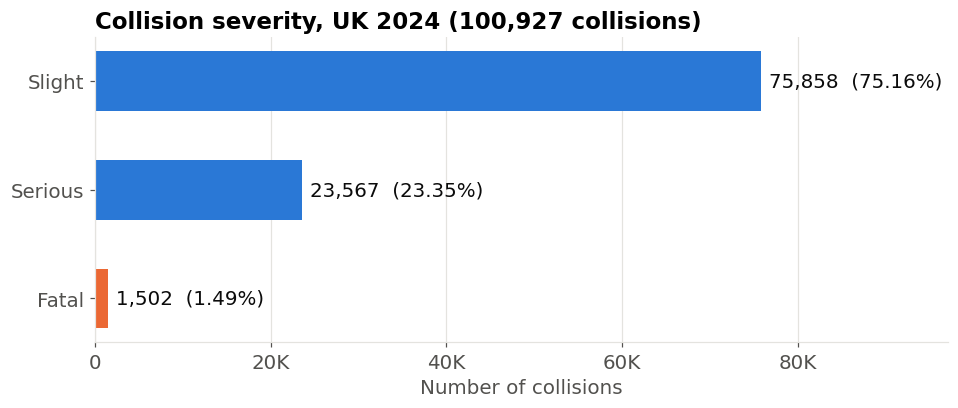

In [5]:
order = ["Slight", "Serious", "Fatal"]
counts = df["severity"].value_counts().reindex(order)
share = counts / counts.sum() * 100
print(pd.DataFrame({"collisions": counts, "share %": share.round(2)}))
print(f"imbalance ratio Slight : Fatal = {counts['Slight']/counts['Fatal']:.0f} : 1")

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [BLUE, BLUE, ORANGE]
ax.barh(order[::-1], counts[order[::-1]], color=colors[::-1], height=0.55)
for i, k in enumerate(order[::-1]):
    ax.text(counts[k] + 900, i, f"{counts[k]:,}  ({share[k]:.2f}%)", va="center", color=INK, fontsize=13)
ax.set_xlim(0, counts.max() * 1.28)
ax.xaxis.set_major_formatter(lambda v, p: f"{int(v/1000)}K" if v else "0")
ax.grid(axis="y", visible=False)
ax.set_title("Collision severity, UK 2024 (100,927 collisions)", loc="left")
ax.set_xlabel("Number of collisions")
save(fig, "01_target_distribution.png")

> **Finding:** fatal collisions are only **1.49%** of the data (51 Slight for every 1 Fatal). A model that always says *Slight* would score 75% accuracy and never find a fatal crash, so accuracy alone is useless here.

## 4. Missing and unknown values

special_conditions_at_site    61.40
journey_purpose               55.59
vehicle_age                   25.97
propulsion_type               25.97
junction_detail               13.24
vehicle_manoeuvre             11.13
second_road_class             11.06
sex_of_driver                 10.84
junction_location              7.44
driver_age                     5.61
towing_and_articulation        4.33
pedestrian_crossing            4.01
weather_conditions             3.12
carriageway_hazards            3.05
road_type                      2.54
road_surface_conditions        2.35
junction_control               1.89
vehicle_type                   0.09
light_conditions               0.01
urban_or_rural_area            0.00
number_of_vehicles             0.00
hour                           0.00
speed_limit                    0.00
dtype: float64


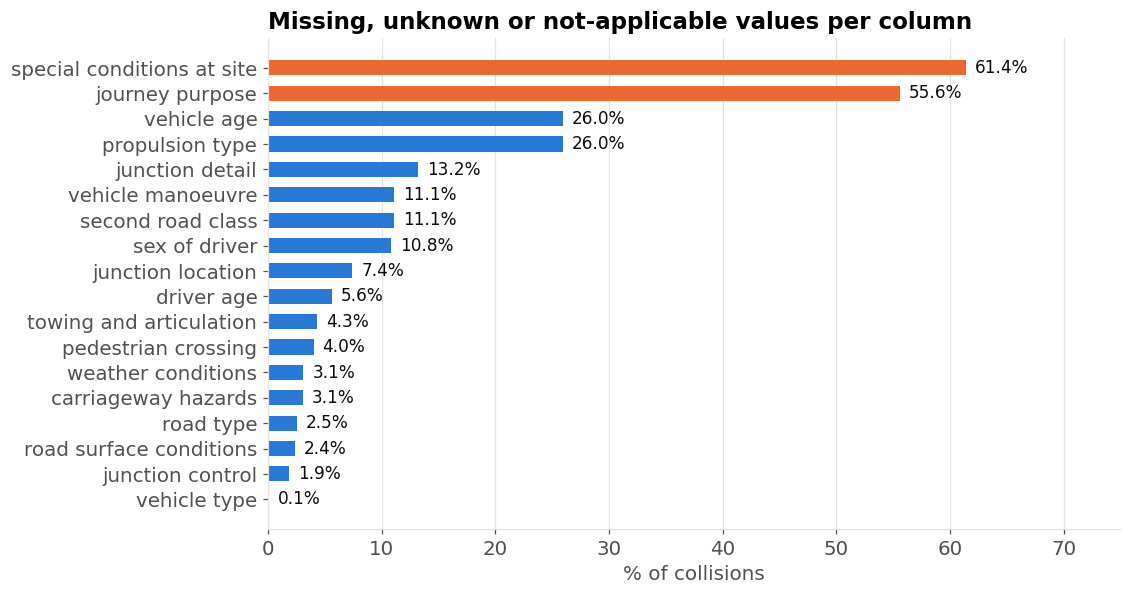

In [6]:
MISSING = {c: {-1, 9} for c in LABELS}
MISSING.update({"junction_detail": {-1, 99}, "pedestrian_crossing": {-1, 99}, "carriageway_hazards": {-1, 99},
                "light_conditions": {-1}, "urban_or_rural_area": {-1, 3}, "day_of_week": set(), "first_road_class": set(),
                "junction_control": {9}})   # junction_control -1 means 'not at a junction', not missing
check = ["speed_limit","road_type","junction_detail","junction_control","second_road_class","pedestrian_crossing",
         "light_conditions","weather_conditions","road_surface_conditions","special_conditions_at_site",
         "carriageway_hazards","urban_or_rural_area","number_of_vehicles","hour"] + VEH_FEATS
miss = {}
for c in check:
    codes = MISSING.get(c, {-1, 9, 99} if c == "special_conditions_at_site" else {-1})
    if c in VEH_FEATS:
        unk_vals = {"Unknown"}
        miss[c] = (df[c].isin(unk_vals) | df[c].isna()).mean() * 100
    else:
        miss[c] = (df[c].isin(codes) | df[c].isna()).mean() * 100
miss = pd.Series(miss).sort_values()
print(miss.round(2).sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(10, 5.8))
show = miss[miss >= 0.05]   # columns with at least 0.05% missing
cols = [ORANGE if v > 50 else BLUE for v in show]
ax.barh(show.index.str.replace("_", " "), show.values, color=cols, height=0.6)
for i, v in enumerate(show.values):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", color=INK, fontsize=11)
ax.set_xlim(0, 75); ax.grid(axis="y", visible=False)
ax.set_title("Missing, unknown or not-applicable values per column", loc="left")
ax.set_xlabel("% of collisions")
save(fig, "02_missing_values.png")

In [7]:
# Are 'unknown' values random? Compare the fatal rate of unknown vs known values.
for c in ["weather_conditions", "road_surface_conditions", "road_type"]:
    unk = df[c].isin({-1, 9})
    print(f"{c:26s} fatal rate  unknown {df.loc[unk,'collision_severity'].eq(1).mean()*100:.2f}%"
          f"  vs known {df.loc[~unk,'collision_severity'].eq(1).mean()*100:.2f}%")
unk_age = df["driver_age"].eq("Unknown")
print(f"{'driver_age':26s} fatal rate  unknown {df.loc[unk_age,'collision_severity'].eq(1).mean()*100:.2f}%  vs known {df.loc[~unk_age,'collision_severity'].eq(1).mean()*100:.2f}%")

weather_conditions         fatal rate  unknown 0.35%  vs known 1.52%
road_surface_conditions    fatal rate  unknown 0.08%  vs known 1.52%
road_type                  fatal rate  unknown 0.19%  vs known 1.52%
driver_age                 fatal rate  unknown 0.34%  vs known 1.56%


> **Finding:** *unknown* values are **not random**: collisions with unknown weather have a fatal rate of 0.35% against 1.52% for the rest. Unknowns come mostly from self-reported, minor collisions. Filling them with the most common value would hide this, so we keep **Unknown as its own category**. Only `special_conditions_at_site` (61% missing) is dropped.

## 5. What makes a collision fatal?

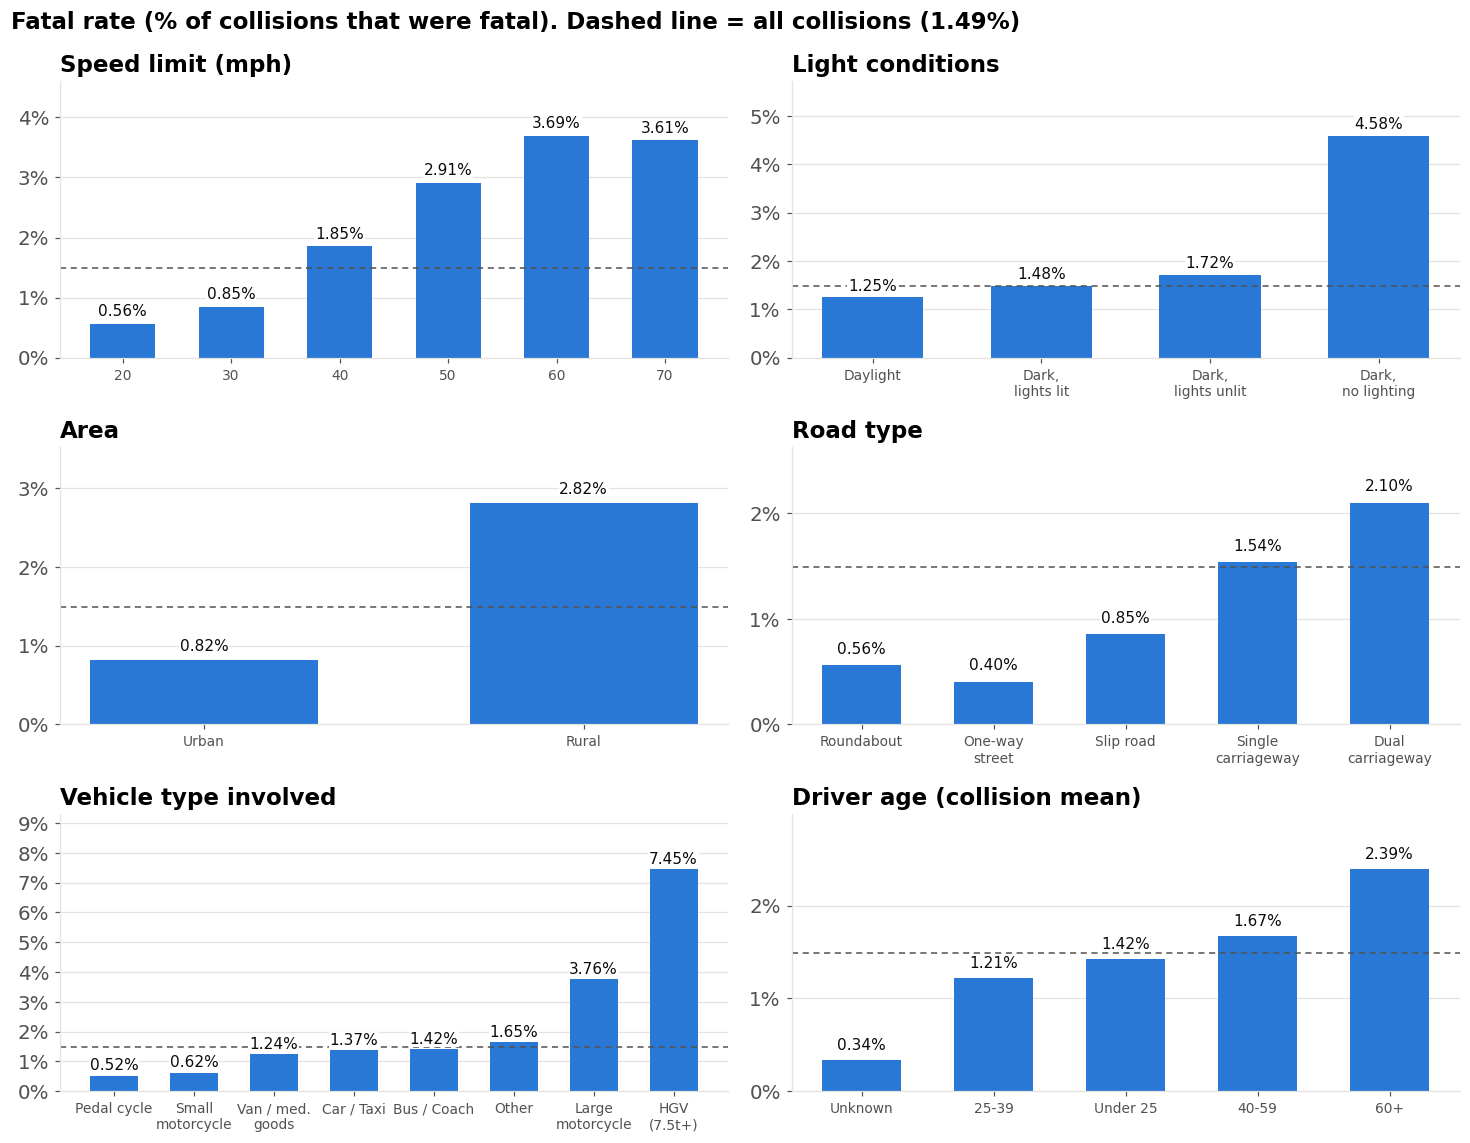

In [8]:
overall = df["collision_severity"].eq(1).mean() * 100
def fatal_rate(col, order=None, data=lab):
    g = data.groupby(col)["collision_severity"].agg(lambda s: (s == 1).mean() * 100)
    n = data.groupby(col).size()
    g = g[n >= 200]                      # ignore tiny groups
    return g.reindex(order).dropna() if order else g.sort_values()

panels = [
    ("Speed limit (mph)", fatal_rate("speed_limit", [20, 30, 40, 50, 60, 70], df)),
    ("Light conditions", fatal_rate("light_conditions", ["Daylight", "Dark, lights lit", "Dark, lights unlit", "Dark, no lighting"])),
    ("Area", fatal_rate("urban_or_rural_area", ["Urban", "Rural"])),
    ("Road type", fatal_rate("road_type", ["Roundabout", "One way street", "Slip road", "Single carriageway", "Dual carriageway"])),
    ("Vehicle type involved", fatal_rate("vehicle_type")),
    ("Driver age (collision mean)", fatal_rate("driver_age", ["Unknown", "25-39", "Under 25", "40-59", "60+"])),
]
fig, axes = plt.subplots(3, 2, figsize=(13.5, 10.6))
for ax, (title, s) in zip(axes.ravel(), panels):
    labels = [
        str(i).replace("Dark, ", "Dark,\n").replace(" carriageway", "\ncarriageway")
        .replace("One way street", "One-way\nstreet")
        .replace("Other (e-scooter / agri / mobility)", "Other")
        .replace("Large / other motorcycle", "Large\nmotorcycle")
        .replace("Moped / small motorcycle", "Small\nmotorcycle")
        .replace("Van / medium goods", "Van / med.\ngoods")
        .replace("Heavy goods (7.5t+)", "HGV\n(7.5t+)")
        for i in s.index
    ]
    bars = ax.bar(labels, s.values, color=BLUE, width=0.6)
    ax.axhline(overall, color=MUTED, lw=1, ls=(0, (4, 3)))
    for b, v in zip(bars, s.values):
        ax.text(b.get_x() + b.get_width()/2, v + 0.08, f"{v:.2f}%", ha="center", va="bottom", fontsize=10, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    ax.set_title(title, loc="left"); ax.set_ylim(0, max(s.max() * 1.25, 2)); ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(plt.MultipleLocator(1)); ax.yaxis.set_major_formatter(lambda v, p: f"{v:g}%")
    ax.tick_params(axis="x", labelsize=9.0)
fig.suptitle(f"Fatal rate (% of collisions that were fatal). Dashed line = all collisions ({overall:.2f}%)",
             x=0.01, ha="left", fontsize=15, fontweight="semibold")
fig.tight_layout()
save(fig, "03_fatal_rate_by_factor.png")

> **Findings:** the fatal rate grows with the **speed limit** (0.56% at 20 mph and 3.69% at 60 mph, about 6.6 times higher), is about **3.7 times higher in darkness without street lights** than in daylight (4.58% against 1.25%), and **3.4 times higher on rural roads** than on urban ones (2.82% against 0.82%). Adding vehicle and driver features shows strong separation as well: collisions involving **heavy goods vehicles (7.5t+)** or **large motorcycles** have much higher fatal rates than cars or pedal cycles, and collisions with drivers aged **60+** are roughly twice as likely to be fatal as those in the **25–39** band.

## 6. When do collisions happen?

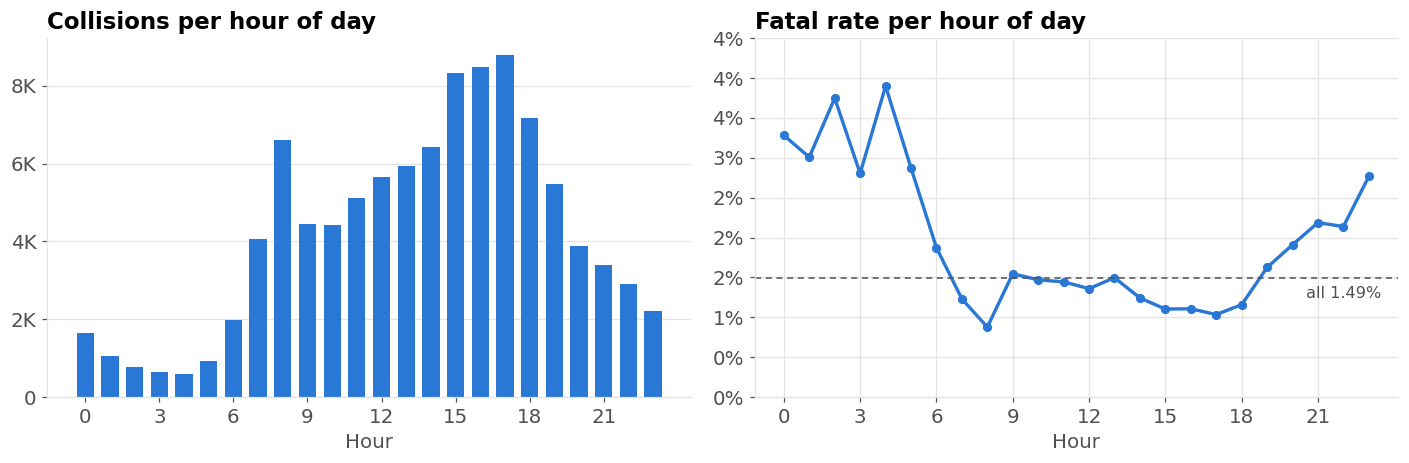

hour        0        1       2      3      4       5        6        7   \
n      1646.00  1064.00  774.00  642.0  590.0  940.00  1976.00  4061.00   
fatal     3.28     3.01    3.75    2.8    3.9    2.87     1.87     1.23   

hour        8        9   ...       14      15       16       17       18  \
n      6603.00  4458.00  ...  6435.00  8328.0  8487.00  8784.00  7159.00   
fatal     0.88     1.55  ...     1.24     1.1     1.11     1.04     1.16   

hour        19       20       21       22       23  
n      5476.00  3872.00  3383.00  2899.00  2205.00  
fatal     1.63     1.91     2.19     2.14     2.77  

[2 rows x 24 columns]


In [9]:
by_hour = df.groupby("hour").agg(n=("collision_severity", "size"),
                                 fatal=("collision_severity", lambda s: (s == 1).mean() * 100))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
a1.bar(by_hour.index, by_hour["n"], color=BLUE, width=0.7)
a1.set_title("Collisions per hour of day", loc="left"); a1.set_xlabel("Hour"); a1.grid(axis="x", visible=False)
a1.yaxis.set_major_formatter(lambda v, p: f"{int(v/1000)}K" if v else "0")
a2.plot(by_hour.index, by_hour["fatal"], color=BLUE, lw=2.2, marker="o", ms=5)
a2.axhline(overall, color=MUTED, lw=1, ls=(0, (4, 3)))
a2.text(23.5, overall - 0.25, f"all {overall:.2f}%", ha="right", color=MUTED, fontsize=10.5)
a2.set_title("Fatal rate per hour of day", loc="left"); a2.set_xlabel("Hour"); a2.set_ylim(0, 4.5)
a2.yaxis.set_major_formatter(lambda v, p: f"{v:.0f}%")
for ax in (a1, a2): ax.set_xticks(range(0, 24, 3))
fig.tight_layout()
save(fig, "04_time_patterns.png")
print(by_hour.round(2).T)

> **Finding:** most collisions happen in the afternoon rush (15:00-17:00, more than 8,300 in each hour), but the **most dangerous hours are at night** (00:00-05:00), with a fatal rate of 3.24%, about 2.6 times the daytime rate (1.22% from 07:00 to 18:00).

## 7. Outliers: number of vehicles

count    100927.00
mean          1.82
std           0.69
min           1.00
25%           1.00
50%           2.00
75%           2.00
max          26.00
Name: number_of_vehicles, dtype: float64
IQR rule: values above 3.5 are outliers -> 1,997 collisions


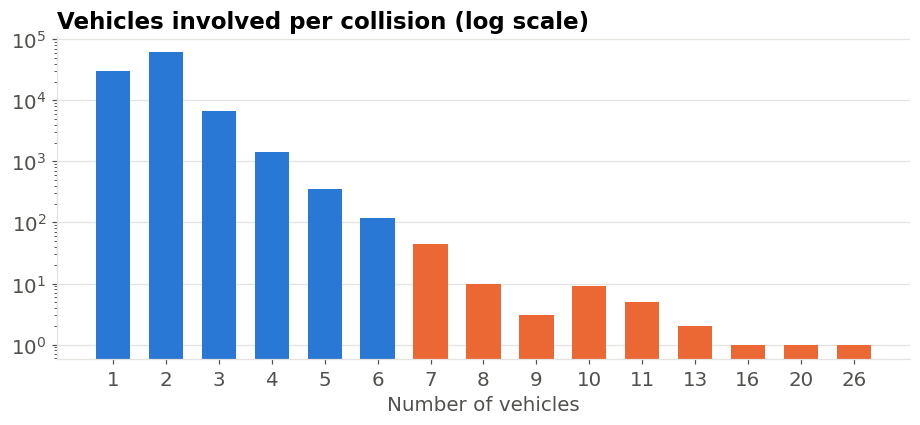

In [10]:
nv = df["number_of_vehicles"]
print(nv.describe().round(2))
q1, q3 = nv.quantile([.25, .75]); iqr = q3 - q1
print(f"IQR rule: values above {q3 + 1.5*iqr:.1f} are outliers -> {(nv > q3 + 1.5*iqr).sum():,} collisions")
fig, ax = plt.subplots(figsize=(10, 3.8))
vc = nv.value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color=[ORANGE if k > 6 else BLUE for k in vc.index], width=0.65)
ax.set_yscale("log"); ax.grid(axis="x", visible=False)
ax.set_title("Vehicles involved per collision (log scale)", loc="left"); ax.set_xlabel("Number of vehicles")
save(fig, "05_number_of_vehicles.png")

> **Finding:** most collisions involve 1 to 3 vehicles; values up to **26** are rare but real (multi-vehicle pile-ups), so we keep them and **cap the value at 6** (6 = six or more), instead of deleting rows.

## 8. Which attributes are most related to severity? (Cramér's V)

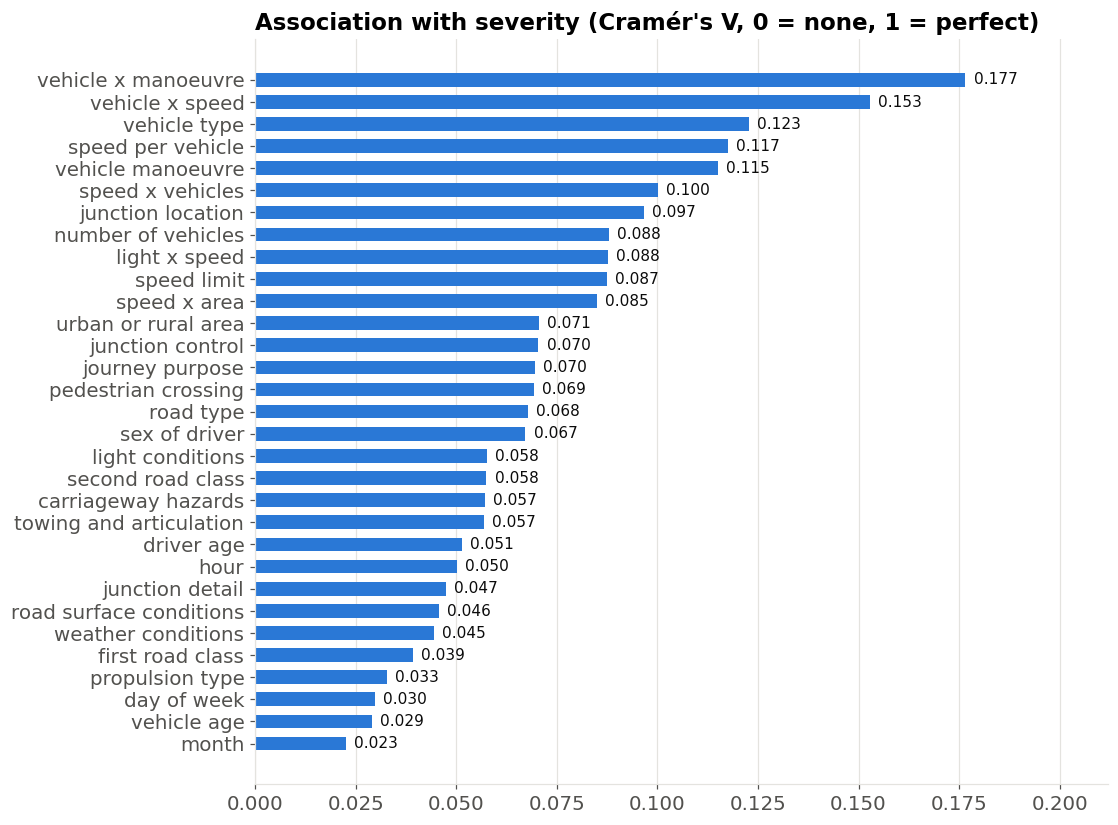

vehicle_x_manoeuvre        0.177
vehicle_x_speed            0.153
vehicle_type               0.123
speed_per_vehicle          0.117
vehicle_manoeuvre          0.115
speed_x_vehicles           0.100
junction_location          0.097
number_of_vehicles         0.088
light_x_speed              0.088
speed_limit                0.087
speed_x_area               0.085
urban_or_rural_area        0.071
junction_control           0.070
journey_purpose            0.070
pedestrian_crossing        0.069
road_type                  0.068
sex_of_driver              0.067
light_conditions           0.058
second_road_class          0.058
carriageway_hazards        0.057
towing_and_articulation    0.057
driver_age                 0.051
hour                       0.050
junction_detail            0.047
road_surface_conditions    0.046
weather_conditions         0.045
first_road_class           0.039
propulsion_type            0.033
day_of_week                0.030
vehicle_age                0.029
month     

In [11]:
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.values.sum(); r, k = t.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

def add_interactions(d):
    out = d.copy()
    sp = pd.to_numeric(out["speed_limit"], errors="coerce").replace(-1, np.nan).fillna(30).astype(int)
    nv = out["number_of_vehicles"].clip(upper=6)
    out["speed_x_vehicles"] = sp * nv
    out["speed_per_vehicle"] = (sp / nv).round(2)
    speed_band = np.where(sp >= 60, "60-70mph", np.where(sp >= 40, "40-50mph", "20-30mph"))
    area = out["urban_or_rural_area"].replace({1:"Urban",2:"Rural",3:"Urban",-1:"Urban","Unallocated":"Urban"})
    dark_flag = np.where(out["light_conditions"].isin([1, "Daylight"]), "Daylight", "Dark")
    out["speed_x_area"] = area.astype(str) + " | " + speed_band
    out["light_x_speed"] = dark_flag + " | " + speed_band
    out["vehicle_x_speed"] = out["vehicle_type"].astype(str) + " | " + speed_band
    out["vehicle_x_manoeuvre"] = out["vehicle_type"].astype(str) + " | " + out["vehicle_manoeuvre"].astype(str)
    return out

df_assoc = add_interactions(df)
feats = ["speed_limit","urban_or_rural_area","number_of_vehicles","vehicle_type","vehicle_manoeuvre","junction_location",
         "light_conditions","first_road_class","junction_detail","road_type","junction_control","driver_age","sex_of_driver",
         "journey_purpose","towing_and_articulation","propulsion_type","vehicle_age","hour","pedestrian_crossing",
         "second_road_class","weather_conditions","road_surface_conditions","carriageway_hazards","day_of_week","month",
         "speed_x_vehicles","speed_per_vehicle","speed_x_area","light_x_speed","vehicle_x_speed","vehicle_x_manoeuvre"]
assoc = pd.Series({f: cramers_v(df_assoc[f], df_assoc["severity"]) for f in feats}).sort_values()
fig, ax = plt.subplots(figsize=(10, 8.8))
ax.barh(assoc.index.str.replace("_", " "), assoc.values, color=BLUE, height=0.62)
for i, v in enumerate(assoc.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=10, color=INK)
ax.set_xlim(0, assoc.max() * 1.2); ax.grid(axis="y", visible=False)
ax.set_title("Association with severity (Cramér's V, 0 = none, 1 = perfect)", loc="left")
save(fig, "06_association_with_severity.png")
print(assoc.sort_values(ascending=False).round(3))

> **Finding:** The engineered pre-crash interactions `vehicle_x_manoeuvre` (**Cramér's V = 0.177**) and `vehicle_x_speed` (**0.153**) hold the strongest individual associations with severity, followed by `vehicle_type` (**0.123**), `speed_per_vehicle` (**0.117**), `vehicle_manoeuvre` (**0.115**), and `speed_x_vehicles` (**0.100**). Adding domain interactions explicitly captures combined collision energy and manoeuvre hazard that single raw columns miss.

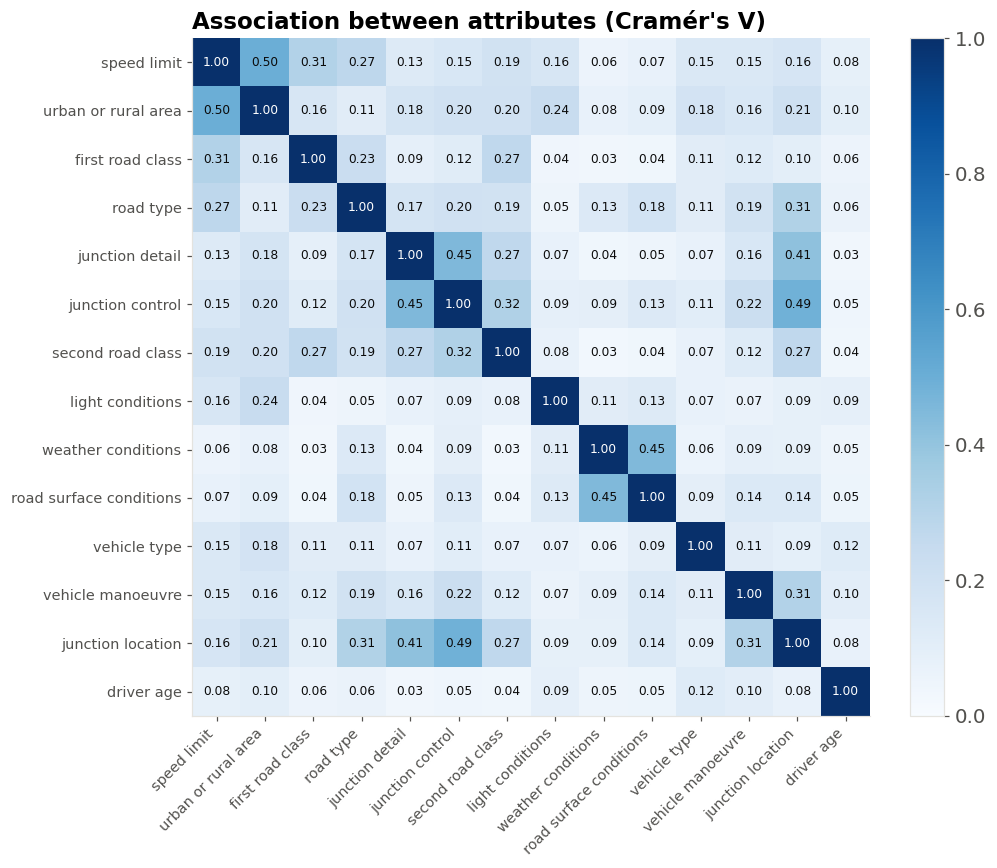

In [12]:
# redundancy check between attributes (Week 4 correlation heatmap, for categorical data)
red = ["speed_limit","urban_or_rural_area","first_road_class","road_type","junction_detail","junction_control",
       "second_road_class","light_conditions","weather_conditions","road_surface_conditions",
       "vehicle_type","vehicle_manoeuvre","junction_location","driver_age"]
M = pd.DataFrame([[cramers_v(df[a], df[b]) for b in red] for a in red], index=red, columns=red)
fig, ax = plt.subplots(figsize=(9.5, 8.0))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(red))); ax.set_yticks(range(len(red)))
ax.set_xticklabels([r.replace("_", " ") for r in red], rotation=45, ha="right", fontsize=9.5)
ax.set_yticklabels([r.replace("_", " ") for r in red], fontsize=9.5); ax.grid(False)
for i in range(len(red)):
    for j in range(len(red)):
        ax.text(j, i, f"{M.iat[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if M.iat[i, j] > 0.6 else INK)
ax.set_title("Association between attributes (Cramér's V)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.046)
save(fig, "07_attribute_heatmap.png")

> **Finding:** strong pairs exist, for example junction detail, junction control and second road class all describe the junction, and weather relates to road surface. We keep them for the tree models (they handle redundancy) and will test removing them with feature selection (Week 6).

## 9. Data issues and how we solve them
| # | Issue | Evidence | Solution |
|---|---|---|---|
| 1 | Severe class imbalance | Fatal 1.49% (51 : 1) | Stratified split; class weights; compare SMOTE-NC and under-sampling (training data only); judge by per-class recall and macro F1 |
| 2 | Values are numeric codes | e.g. light = 6 | Map every code to its label (STATS20 2024) |
| 3 | Missing / unknown values | up to ~56% *Unknown* in optional vehicle fields; 61% in `special_conditions_at_site` | Keep *Unknown* as a category (it is informative); impute the mode for <0.01% gaps; drop `special_conditions_at_site` |
| 4 | Target leakage | casualty counts and adjusted severity are outcomes | Drop `number_of_casualties`, `enhanced_severity_collision`, `collision_adjusted_severity_*`, `collision_injury_based`, `did_police_officer_attend` |
| 5 | Date, time & interaction effects | `03/05/2024`, `07:30`; risk depends on combined conditions | Extract **month** & **hour**, plus 6 pre-crash interaction features (`speed_x_vehicles`, `speed_per_vehicle`, `speed_x_area`, `light_x_speed`, `vehicle_x_speed`, `vehicle_x_manoeuvre`) |
| 6 | Outliers | up to 26 vehicles | Cap at 6 (binning), keep the rows |
| 7 | Useless or ID columns | IDs, coordinates, constant year, 351 district codes | Drop them |
| 8 | Many categories for some models | 25 categorical attributes | One-hot encoding inside the model pipeline (Week 6) |

## 10. Build the final dataset

In [13]:
final = lab.copy()
# 1) tiny gaps -> mode (speed limit: 3 rows, light: 6 rows, area: 3 rows)
final["speed_limit"] = final["speed_limit"].replace(-1, np.nan).fillna(final["speed_limit"].replace(-1, np.nan).mode()[0]).astype(int)
final["light_conditions"] = final["light_conditions"].replace("Unknown", final["light_conditions"].mode()[0])
final["urban_or_rural_area"] = final["urban_or_rural_area"].replace("Unallocated", final["urban_or_rural_area"].mode()[0])
# 2) outliers -> cap at 6 vehicles
final["number_of_vehicles"] = final["number_of_vehicles"].clip(upper=6)
# 3) engineer 6 strictly pre-crash interaction features
final = add_interactions(final)
# 4) leakage, IDs, location, constant and mostly-missing columns are left out by choosing what we keep
keep = [
    "month","day_of_week","hour","first_road_class","road_type","speed_limit","junction_detail","junction_control",
    "second_road_class","pedestrian_crossing","light_conditions","weather_conditions","road_surface_conditions",
    "carriageway_hazards","urban_or_rural_area","number_of_vehicles",
    "vehicle_type","driver_age","sex_of_driver","vehicle_manoeuvre","junction_location",
    "journey_purpose","towing_and_articulation","propulsion_type","vehicle_age",
    "speed_x_vehicles","speed_per_vehicle","speed_x_area","light_x_speed","vehicle_x_speed","vehicle_x_manoeuvre",
    "severity",
]
final = final[keep]
assert final.isna().sum().sum() == 0
final.to_csv(OUT, index=False)
assert pd.read_csv(OUT).isna().sum().sum() == 0   # read it back: no label may turn into a missing value
print(f"raw   : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"final : {final.shape[0]:,} rows x {final.shape[1]} columns  (31 features + target), no missing cells")
print(final["severity"].value_counts(normalize=True).mul(100).round(2))
final.head()

raw   : 100,927 rows x 44 columns
final : 100,927 rows x 32 columns  (31 features + target), no missing cells
severity
Slight     75.16
Serious    23.35
Fatal       1.49
Name: proportion, dtype: float64


,month,day_of_week,hour,first_road_class,road_type,speed_limit,junction_detail,junction_control,second_road_class,pedestrian_crossing,...,towing_and_articulation,propulsion_type,vehicle_age,speed_x_vehicles,speed_per_vehicle,speed_x_area,light_x_speed,vehicle_x_speed,vehicle_x_manoeuvre,severity
0,5,Fri,7,Unclassified,Single carriageway,30,T or staggered,Give way / uncontrolled,Unclassified,Zebra,...,No tow / articulation,Unknown,Unknown,60,15.0,Urban | 20-30mph,Daylight | 20-30mph,Pedal cycle | 20-30mph,Pedal cycle | Going ahead,Slight
1,11,Thu,5,Unclassified,Single carriageway,20,Crossroads,Give way / uncontrolled,Unclassified,None within 50 m,...,No tow / articulation,Unknown,Unknown,40,10.0,Urban | 20-30mph,Dark | 20-30mph,Pedal cycle | 20-30mph,Pedal cycle | Going ahead,Serious
2,4,Thu,18,Unclassified,Dual carriageway,40,Not at junction,Not at junction,Not at junction,None within 50 m,...,No tow / articulation,Unknown,Unknown,80,20.0,Rural | 40-50mph,Daylight | 40-50mph,Car / Taxi | 40-50mph,Car / Taxi | Going ahead,Slight
3,5,Thu,21,Unclassified,Single carriageway,20,T or staggered,Traffic signal,A,Pedestrian phase at signal,...,No tow / articulation,Unknown,Unknown,20,20.0,Urban | 20-30mph,Dark | 20-30mph,Pedal cycle | 20-30mph,Pedal cycle | Going ahead,Serious
4,7,Fri,16,Unclassified,Single carriageway,20,T or staggered,Give way / uncontrolled,Unclassified,Pedestrian light crossing,...,No tow / articulation,Unknown,Unknown,20,20.0,Urban | 20-30mph,Daylight | 20-30mph,Pedal cycle | 20-30mph,Pedal cycle | Going ahead,Serious


In [14]:
# data types of the final features (Week 4 taxonomy)
num_cols = ("hour","month","number_of_vehicles","speed_limit","speed_x_vehicles","speed_per_vehicle")
types = pd.DataFrame({"type": ["numerical" if c in num_cols else
                               ("target" if c == "severity" else "categorical (nominal)") for c in final.columns],
                      "distinct values": final.nunique().values}, index=final.columns)
types

,type,distinct values
month,numerical,12
day_of_week,categorical (nominal),7
hour,numerical,24
first_road_class,categorical (nominal),6
road_type,categorical (nominal),6
speed_limit,numerical,6
junction_detail,categorical (nominal),7
junction_control,categorical (nominal),6
second_road_class,categorical (nominal),8
pedestrian_crossing,categorical (nominal),9
